# Spatial 2D object hidden state

Explore how loading history changes internal state and the response to a later action.

Open the project with **Dev Containers: Reopen in Container**, select **NR 2D (Docker)**, and **Run All**.
The default computes a fresh main trajectory and replays saved checks, forecasts and history sweeps.
Use **Recompute** for a new calculation; the timeline replays the trajectory.

[Setup and commands](../docs/CONTAINER.md) | [Model and results](../docs/README.md)


In [1]:
from pathlib import Path
import os
import sys
import time

ROOT = next((p for base in [Path.cwd(), *Path.cwd().parents]
             for p in (base, base / '2D') if (p / 'src/nr2d/physics.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Open the NR-material-state folder in VS Code and run from this project.')
sys.path.insert(0, str(ROOT / 'src'))
get_ipython().run_line_magic('matplotlib', 'widget')

import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from nr2d.physics import Config, SpatialModel, Trace
from nr2d.protocols import protocol
from nr2d.experiments import run_pilot, read_json, write_json, forecasts_for, sweep_for
from nr2d.plotting import archived_history_figure, paired_figure, export_figure
from nr2d.widgets import ReplayDashboard, ForecastDashboard, SweepDashboard, checks_table, matching_table, table
import ipywidgets as widgets

NOTEBOOK_START = time.perf_counter()
CONFIG_PATH = ROOT / 'configs/spatial_contact.json'
config = Config(**read_json(CONFIG_PATH))
RECOMPUTE_PILOT = False
print('Python:', sys.executable)
print('Project:', ROOT)


Python: /usr/local/bin/python
Project: /workspaces/NR-material-state/2D


## 0. Existing evidence

The archived **history-dependence** study motivates the spatial experiment. Classical observers were competitive;
the shared-feedback study found no useful action benefit. The remaining sections use the 2D solver.


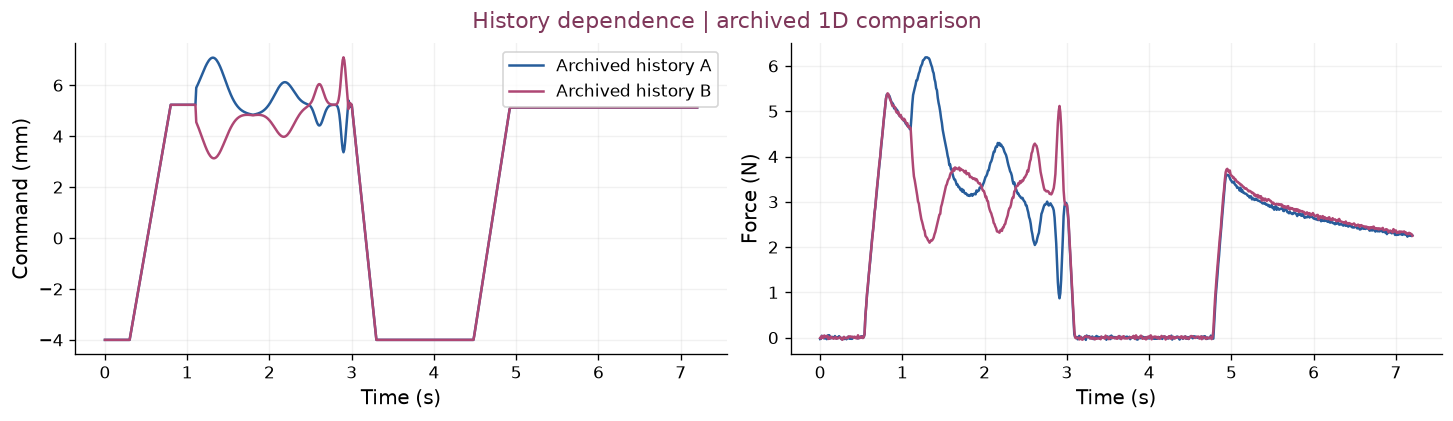

Archived source: 1D/experiments/history_dependence/runs/round2_v1/data/test_wait.npz


In [2]:
from io import BytesIO
with plt.ioff():
    archived_fig, archived_source = archived_history_figure()
buffer = BytesIO()
archived_fig.savefig(buffer, format='png', dpi=120, bbox_inches='tight')
display(Image(data=buffer.getvalue()))
plt.close(archived_fig)
print('Archived source:', archived_source.relative_to(ROOT.parent))


## 1. Physical process: load, hold, release, wait, recontact

A circular indenter presses a 40 x 20 mm plane-strain body with a fixed bottom and free sides.
The FEM body is quasistatic; the tool has inertia and a compliant, damped actuator. Lateral displacement comes from the coupled solve.

The synthetic two-mode material follows

$$
\sigma = C_\infty\epsilon + \sum_{i\in\{f,s\}} C_i(\epsilon-z_i),\qquad
\dot z_i=(\epsilon-z_i)/\tau_i.
$$

The physical state contains internal-strain fields $z_f,z_s$ and tool position/velocity, with fixed material and geometry.
Displacement and contact follow from equilibrium. Command, achieved motion and contact reaction are recorded separately at 100 Hz.


In [3]:
run, runtime = run_pilot(config, force=RECOMPUTE_PILOT, progress=print)
manifest = read_json(run / 'manifest.json')
report = read_json(run / 'checks.json')
from datetime import datetime
commands, phases, _ = protocol(Config(**read_json(run / 'config.json')))
main = SpatialModel(Config(**read_json(run / 'config.json'))).simulate(
    commands, phases, metadata={'source': 'Fresh notebook spatial 2D solve', 'role': 'demonstration'})
live_dir = run / 'notebook_runs' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
main.save(live_dir / 'main.npz')
write_json(live_dir / 'execution.json', {'solver_seconds': main.wall_seconds, 'source': 'fresh main episode',
                                      'config': main.config, 'verification_cache': str(run / 'checks.json')})
print('Mode:', runtime['mode'])
print('This numerical entry call: %.2f s; recorded cold pilot: %.2f s' %
      (runtime['wall_seconds'], manifest['wall_seconds']))
print('Run:', run)
print('Synthetic parameters:', main.config)
print('FRESH main spatial solve: %.2f s; verification table below replays the checked numerical pilot.' % main.wall_seconds)
display(checks_table(report))


REPLAY: verified cached spatial 2D pilot (pilot_c9dd23016896)


Mode: REPLAY
This numerical entry call: 0.03 s; recorded cold pilot: 72.34 s
Run: /workspaces/NR-material-state/2D/runs/2d_contact/pilot_c9dd23016896
Synthetic parameters: {'nx': 24, 'ny': 12, 'width': 0.04, 'height': 0.02, 'thickness': 0.01, 'radius': 0.03, 'E_inf': 20000.0, 'E_fast': 40000.0, 'E_slow': 60000.0, 'nu': 0.35, 'tau_fast': 0.12, 'tau_slow': 0.9, 'tool_mass': 0.04, 'actuator_k': 5000.0, 'actuator_c': 12.0, 'penalty': 2000000000.0, 'dt': 0.01, 'clearance': 0.00015, 'newton_tol': 1e-08, 'newton_max': 35}
FRESH main spatial solve: 1.34 s; verification table below replays the checked numerical pilot.


HTML(value='<table><thead><tr><th style="padding:6px 12px;border-bottom:1px solid #ddd;text-align:left">Physic…

In [4]:
replay = ReplayDashboard(main)
display(replay.widget)


**Reading the animation.** Geometry uses 1x displacement scale. Color shows slow internal strain (simulation truth),
orange points show contact, and teal points show lateral sensors. The three curves share the mesh's time cursor.
After separation, contact force is zero while internal strain and lateral shape continue recovering.

The check table covers relaxation/recovery references, an elastic control, force balance, contact and numerical refinement.


## 2. Why the current observation may be insufficient

Each history starts relaxed and follows a feasible command sequence. Pair selection uses current tool position, velocity,
force and both lateral markers, taking the first accepted pair in fixed ID order. Future response is excluded from selection.
Material, geometry, tool, current command and elapsed time are shared.

The table reports matching residuals. The 5 um lateral band is a matching tolerance; estimators still receive raw marker values
and can use differences within it. The pair demonstrates similar endpoints, with some instantaneous shape information remaining.


HTML(value='<table><thead><tr><th style="padding:6px 12px;border-bottom:1px solid #ddd;text-align:left">Curren…

Accepted / attempted: 28 / 28
Independent test histories: 8


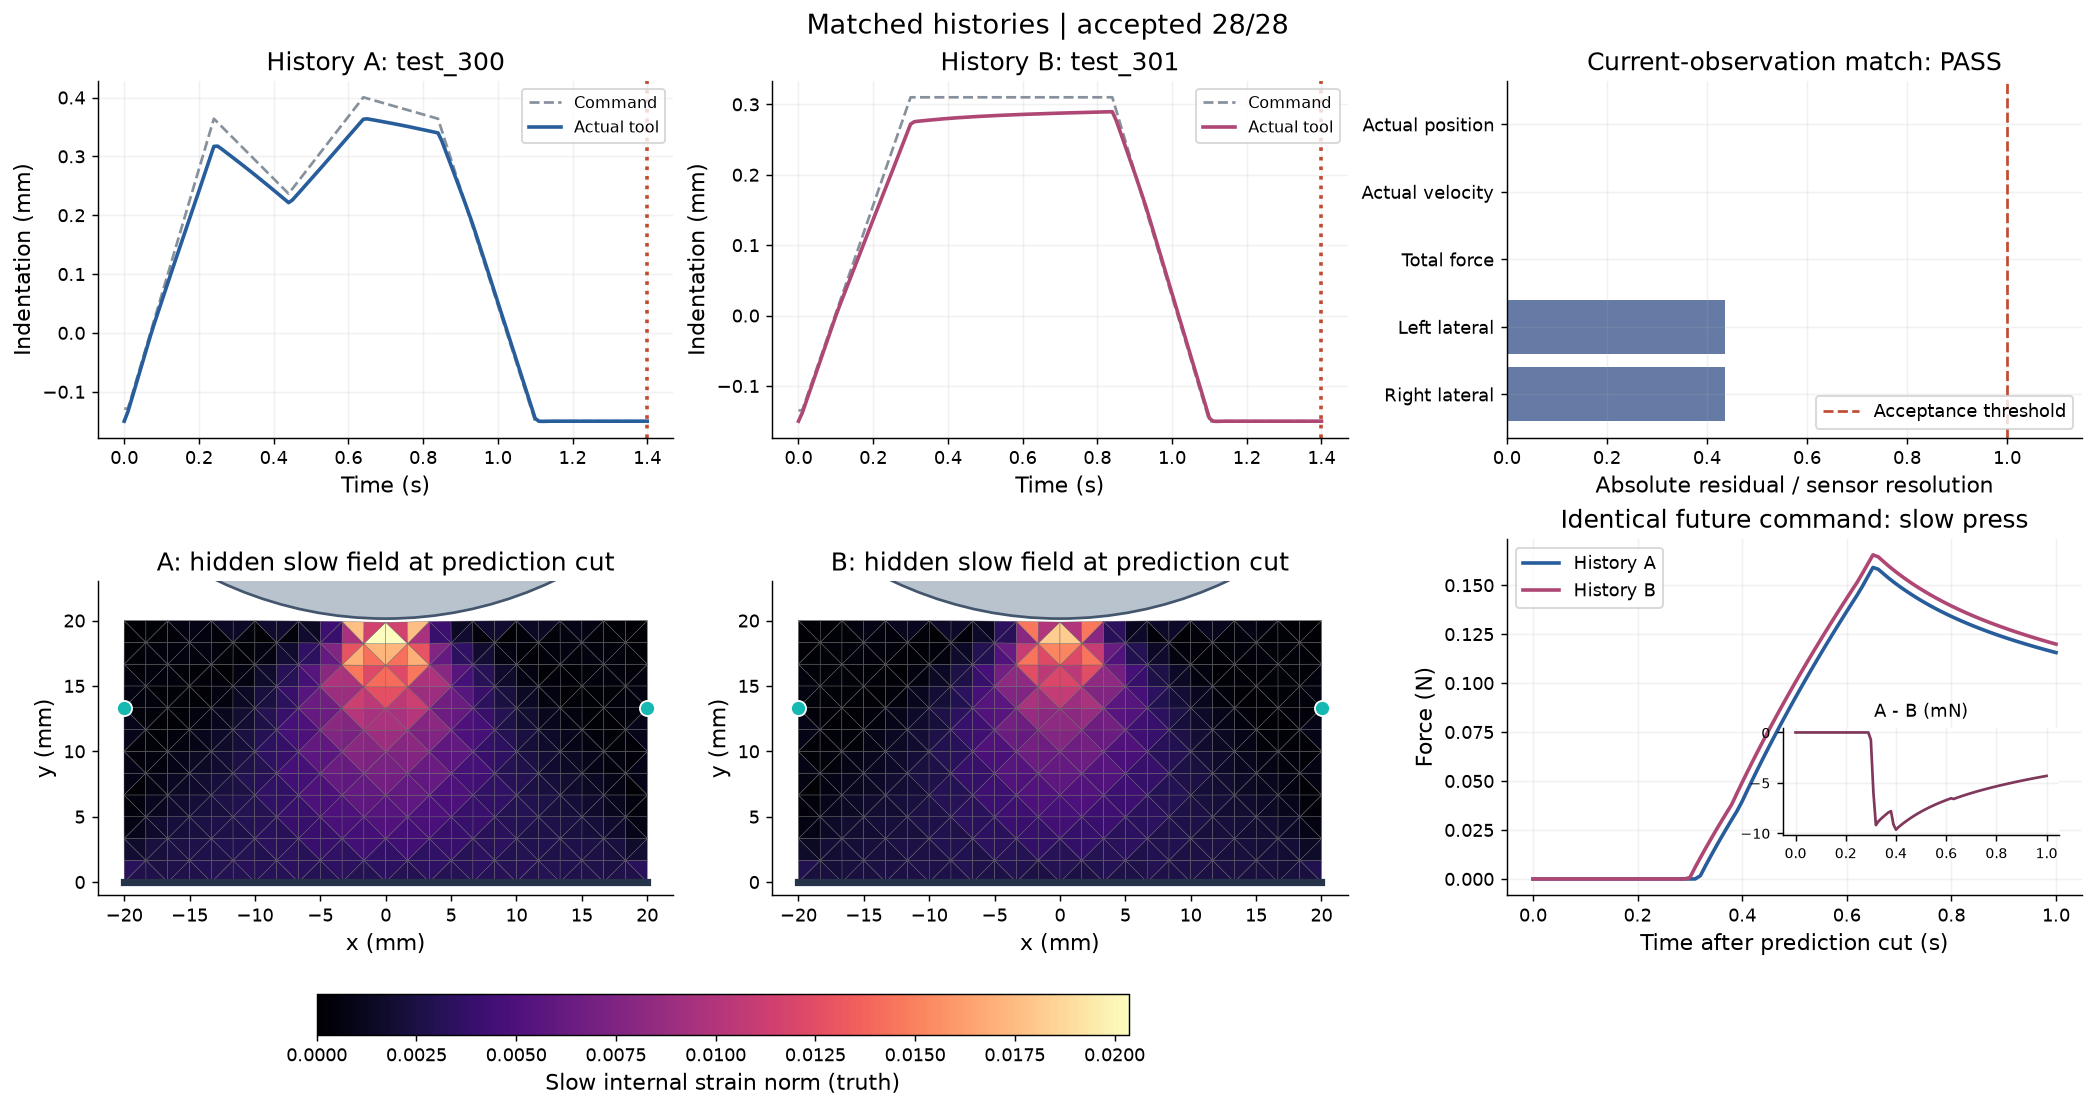

Future force-contrast RMS: 5.583 mN (default), 5.598 mN (fine mesh)
Contrast change under mesh refinement: 0.382 mN RMS


In [5]:
matching = read_json(run / 'matching.json')
display(matching_table(run))
print('Accepted / attempted:', matching['accepted'], '/', matching['attempted'])
print('Independent test histories:', manifest['independent_test_history_count'])
with plt.ioff():
    pair_fig = paired_figure(run)
buffer = BytesIO()
pair_fig.savefig(buffer, format='png', dpi=130, bbox_inches='tight')
display(Image(data=buffer.getvalue()))
plt.close(pair_fig)
refinement = read_json(run / 'pair_refinement.json')
print('Future force-contrast RMS: %.3f mN (default), %.3f mN (fine mesh)' %
      (refinement['default']['force_contrast_rms_N']*1e3, refinement['fine']['force_contrast_rms_N']*1e3))
print('Contrast change under mesh refinement: %.3f mN RMS' % (refinement['contrast_discretization_rms_N']*1e3))


## 3. One checkpoint, several future actions

Choose History A/B and a future action, then press **Run selected future**.
Each method receives the same future command and known model parameters. Hold/Release at this detached checkpoint give zero contact force.

| Method | Information and approximation |
|---|---|
| Snapshot | Current position, velocity, force and two markers; six-coefficient initial-strain basis, minimum-norm fit |
| Short classical | The last 0.2 s; same sensors, fitting basis and optimizer cap |
| Full classical | Complete measured motion and a known relaxed start; exact-model replay |
| True state | Complete internal fields from simulation; reference for the selected future command |

Predictions use past measurements and future commands. Snapshot/window fits use force and lateral observations;
full replay uses measured motion with its known initial state. Inference time is reported because the algorithms have different costs.


In [6]:
forecast = ForecastDashboard(run)
display(forecast.widget)


## 4. How much history is needed?

Compare 0, 0.04, 0.1, 0.2, 0.4, 0.8 s and full history on validation histories.
Synthetic nominal noise is 0.5 um position, 0.01 mm/s velocity, 1.5 mN force and 1 um per marker,
with the same realization used across methods. Samples are synchronous. Pulse excitation changes the loading commands.

Select excitation and noise, then run the sweep. Inspect the curve and fit status to see when extra history helps.


In [7]:
sweep = SweepDashboard(run)
display(sweep.widget)


**Noise changes the result.** Short windows can perform worse than snapshot under nominal noise.
The plots use two validation histories; `RESULTS.md` reports the batch over all eight test histories.


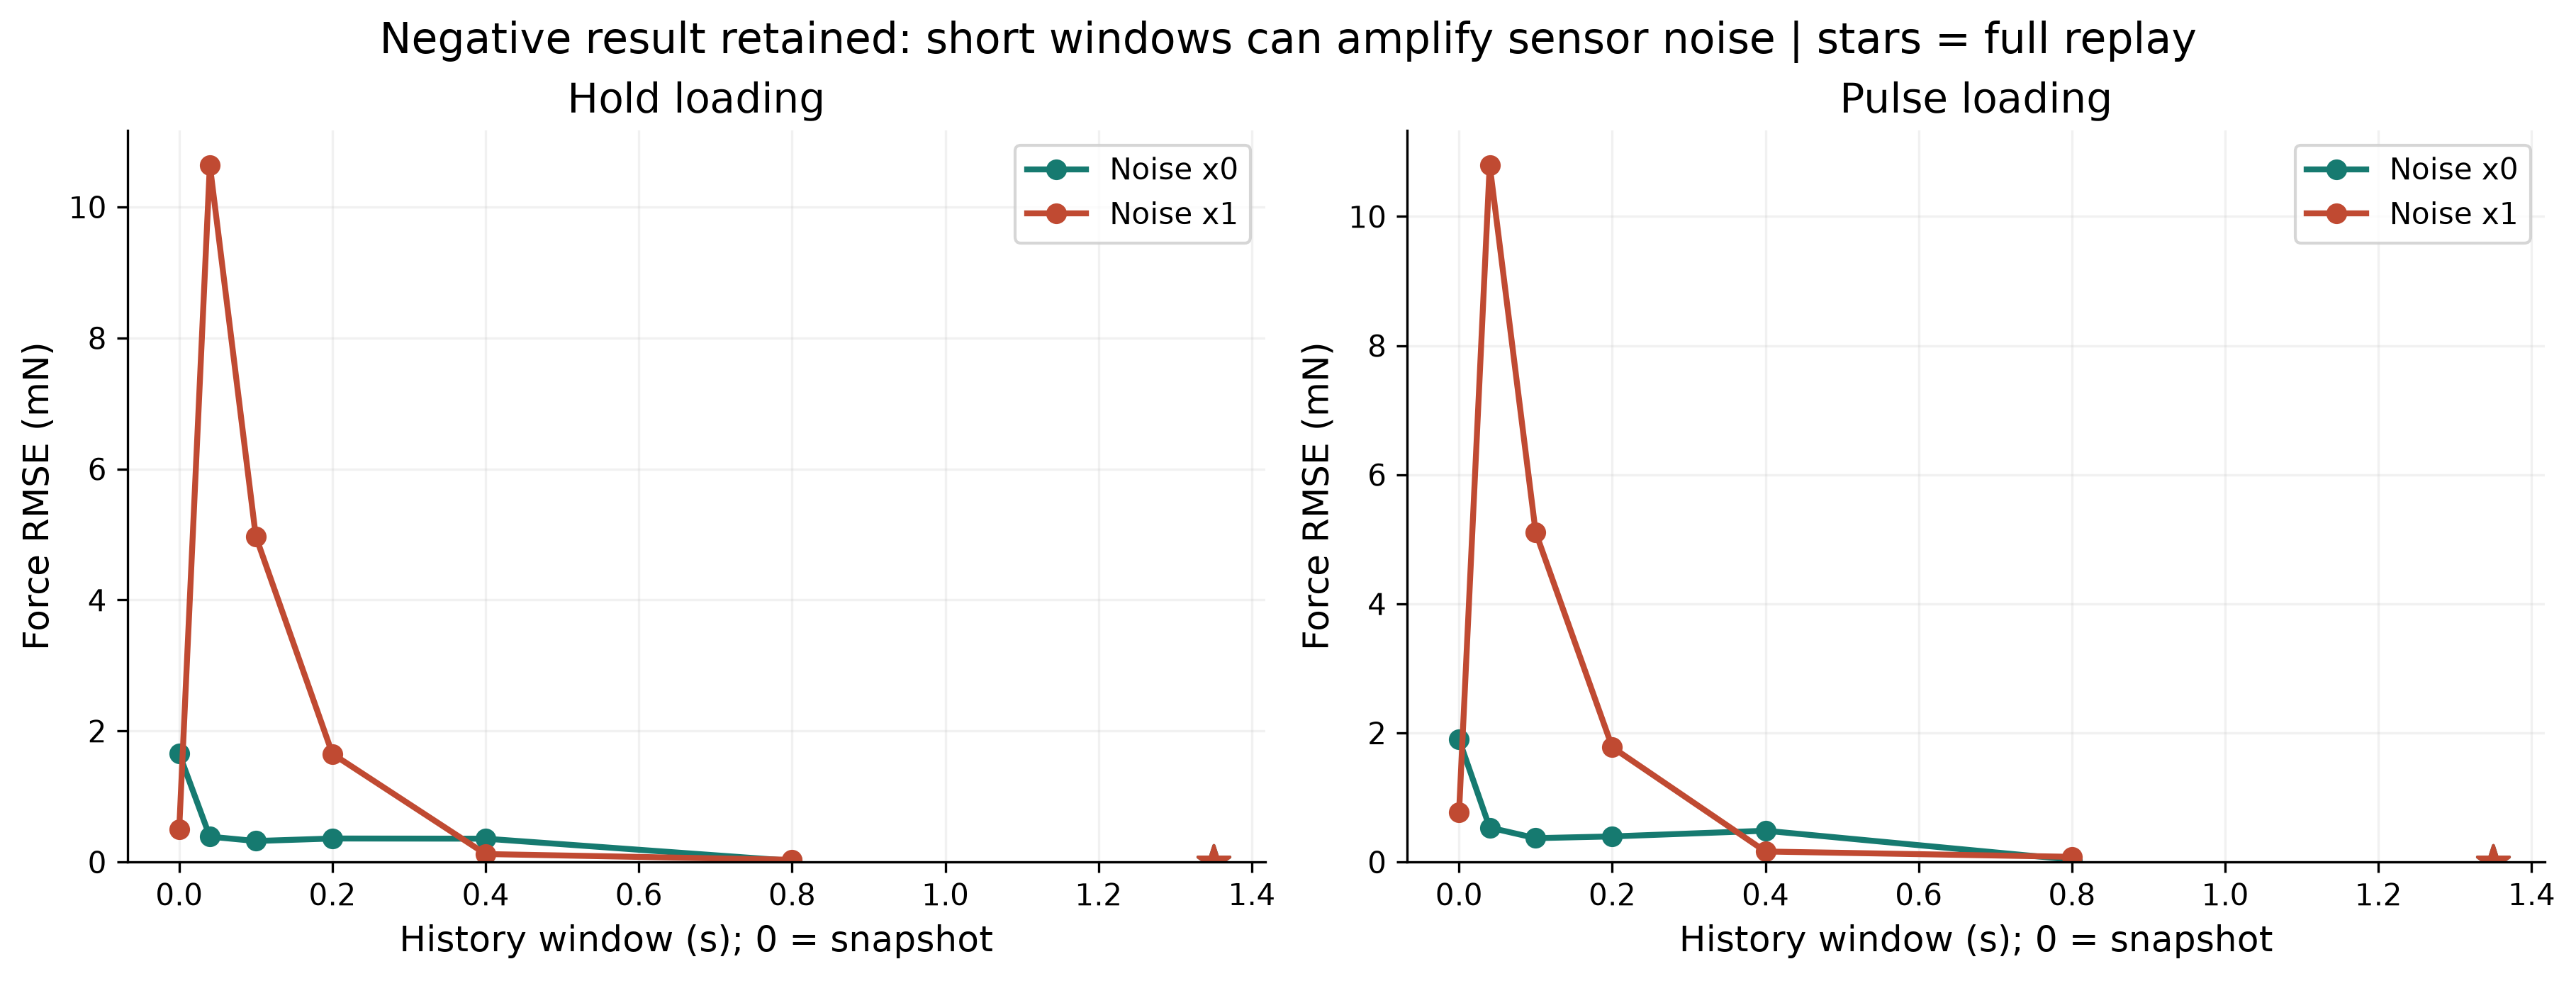

RETAINED physical overrun: histories\validation_200.npz penetration 5.0247 um > 5 um
Diagnostic doubled penalty: 2.6450 um; original is preserved, diagnostic excluded from tests.


In [8]:
noise_preview = run / 'figures/05_noise_and_excitation.png'
if noise_preview.exists():
    display(Image(filename=str(noise_preview)))
else:
    print('Use the noise/excitation dropdowns above to compute and inspect each condition.')
audit_path = run / 'physical_failures.json'
if audit_path.exists():
    audit_failures = read_json(audit_path)
    for item in audit_failures:
        print('RETAINED physical overrun:', item['path'], 'penetration %.4f um > 5 um' % item['max_penetration_um'])
        if 'diagnostic' in item:
            print('Diagnostic doubled penalty: %.4f um; original is preserved, diagnostic excluded from tests.' %
                  item['diagnostic']['max_penetration_um'])


## Findings and next experiment

- Fast/slow internal fields persist after release and affect later contact in this synthetic spatial model.
- Lateral observations constrain those fields. Endpoint residuals matter when comparing history with snapshot.
- The 0.2 s observer improves mean prediction without noise but loses to snapshot under nominal noise across eight test histories.
- Full replay is nearly exact with a known relaxed start and correct model. The results support classical baselines and a measured choice of history length; a learned model needs an additional demonstrated gap.

These are small-strain, same-material prediction experiments with one noise realization per condition. Decision benefit and transfer
remain to be tested. Next, tune noise weighting on calibration histories, then evaluate new histories with independent noise,
varied waits and parameter mismatch. Follow with common-feedback control and full 3D robot simulation before hardware operation.

**Three-minute presentation:** physical recovery -> matched endpoints -> future-action curves -> history length and noise.


In [9]:
metrics = forecasts_for(run)[1]
display(widgets.HTML(table(['Default selected test parent', 'Force RMSE (mN)', 'Lateral RMSE (um)'],
    [[name, '%.4g' % (m['force_rmse_N']*1e3), '%.4g' % (m['marker_rmse_m']*1e6)]
     for name, m in metrics.items()])))
print('Notebook body elapsed: %.2f s (cached pilot and widgets included)' % (time.perf_counter()-NOTEBOOK_START))
print('Figures / GIF:', run / 'figures')
print('Full batch: python -m nr2d.cli batch')
print('Fresh pilot: python -m nr2d.cli demo --recompute')
print('Vector/raster/GIF export: python -m nr2d.cli export')
print('Configuration, raw traces, matching, inference logs and source hashes are stored in the run folder.')


HTML(value='<table><thead><tr><th style="padding:6px 12px;border-bottom:1px solid #ddd;text-align:left">Defaul…

Notebook body elapsed: 4.73 s (cached pilot and widgets included)
Figures / GIF: /workspaces/NR-material-state/2D/runs/2d_contact/pilot_c9dd23016896/figures
Full batch: python -m nr2d.cli batch
Fresh pilot: python -m nr2d.cli demo --recompute
Vector/raster/GIF export: python -m nr2d.cli export
Configuration, raw traces, matching, inference logs and source hashes are stored in the run folder.
